In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df=pd.read_csv("star.csv")
df

,CUST_ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.40,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.00,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.00,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.00,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.00,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8945,C19186,28.493517,1.000000,291.12,0.00,291.12,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,325.594462,48.886365,0.500000,6
8946,C19187,19.183215,1.000000,300.00,0.00,300.00,0.000000,1.000000,0.000000,0.833333,0.000000,0,6,1000.0,275.861322,NaN,0.000000,6
8947,C19188,23.398673,0.833333,144.40,0.00,144.40,0.000000,0.833333,0.000000,0.666667,0.000000,0,5,1000.0,81.270775,82.418369,0.250000,6
8948,C19189,13.457564,0.833333,0.00,0.00,0.00,36.558778,0.000000,0.000000,0.000000,0.166667,2,0,500.0,52.549959,55.755628,0.250000,6


In [3]:
df.isnull().sum()

CUST_ID                               0
BALANCE                               0
BALANCE_FREQUENCY                     0
PURCHASES                             0
ONEOFF_PURCHASES                      0
INSTALLMENTS_PURCHASES                0
CASH_ADVANCE                          0
PURCHASES_FREQUENCY                   0
ONEOFF_PURCHASES_FREQUENCY            0
PURCHASES_INSTALLMENTS_FREQUENCY      0
CASH_ADVANCE_FREQUENCY                0
CASH_ADVANCE_TRX                      0
PURCHASES_TRX                         0
CREDIT_LIMIT                          1
PAYMENTS                              0
MINIMUM_PAYMENTS                    313
PRC_FULL_PAYMENT                      0
TENURE                                0
dtype: int64

In [4]:
df.drop(['MINIMUM_PAYMENTS','CREDIT_LIMIT','CUST_ID'],axis=1,inplace=True)

In [5]:
from sklearn.cluster import KMeans
wcss=[]
for i in range(1,11):
    kmeans = KMeans(n_clusters= i, init='k-means++', random_state=0)
    kmeans.fit(df)
    wcss.append(kmeans.inertia_)

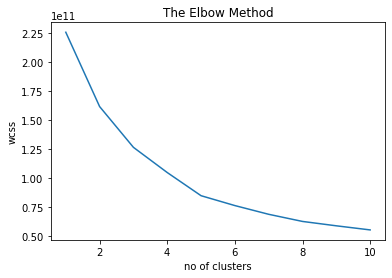

In [6]:
plt.plot(range(1,11),wcss)
plt.title('The Elbow Method')
plt.xlabel('no of clusters')
plt.ylabel('wcss')
plt.show()

In [24]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters= 4, init='k-means++', random_state=0)
y_kmeans=kmeans.fit_predict(df)

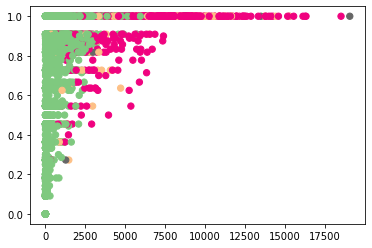

In [25]:
X=np.array(df)
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=40, cmap = "Accent")

In [9]:
import sklearn.metrics as metrics
import sklearn.cluster as cluster

In [10]:
for i in range(3,13):
    labels=cluster.KMeans(n_clusters=i,init="k-means++",random_state=200).fit(X).labels_
    print ("Silhouette score for k(clusters) = "+str(i)+" is "
           +str(metrics.silhouette_score(X,labels,metric="euclidean",sample_size=1000,random_state=200)))

Silhouette score for k(clusters) = 3 is 0.5209358964646824
Silhouette score for k(clusters) = 4 is 0.5731105531896359
Silhouette score for k(clusters) = 5 is 0.5161989131741517
Silhouette score for k(clusters) = 6 is 0.4555726054839307
Silhouette score for k(clusters) = 7 is 0.4514018954949466
Silhouette score for k(clusters) = 8 is 0.3912130774727449
Silhouette score for k(clusters) = 9 is 0.3645551503452548
Silhouette score for k(clusters) = 10 is 0.365663324804289
Silhouette score for k(clusters) = 11 is 0.3662322069431932
Silhouette score for k(clusters) = 12 is 0.3676314618659121


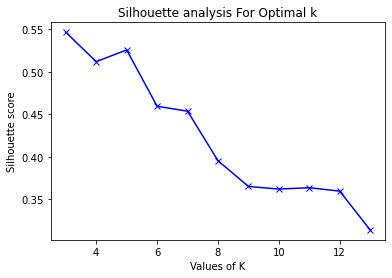

In [11]:
from sklearn.metrics import silhouette_score

range_n_clusters = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
silhouette_avg = []
for num_clusters in range_n_clusters:
    kmeans = KMeans(n_clusters=num_clusters)
    kmeans.fit(X)
    cluster_labels = kmeans.labels_
    silhouette_avg.append(silhouette_score(X, cluster_labels))
plt.plot(range_n_clusters,silhouette_avg,'bx-')
plt.xlabel('Values of K') 
plt.ylabel('Silhouette score') 
plt.title('Silhouette analysis For Optimal k')
plt.show()


In [12]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters= 5, init='k-means++', random_state=0)
y_kmeans=kmeans.fit_predict(df)

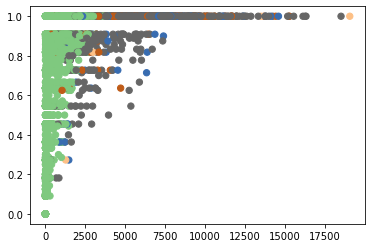

In [13]:
X=np.array(df)
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=40, cmap = "Accent")

In [14]:
from sklearn.mixture import GaussianMixture
gmm=GaussianMixture(n_components=4)
gmm.fit(df)
labels=gmm.predict(df)

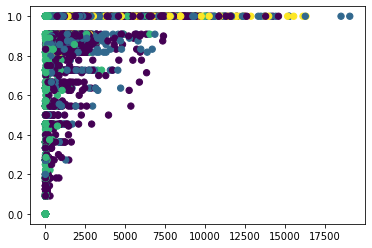

In [15]:
X=np.array(df)
plt.scatter(X[:,0],X[:,1],c=labels,s=40,cmap="viridis")

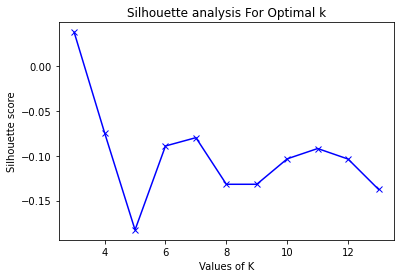

In [17]:
range_n_clusters = [3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13]
silhouette_avg = []
for num_clusters in range_n_clusters:
    gmm1  =GaussianMixture(n_components=num_clusters)
    gmm1.fit(X)
    labels=gmm1.fit_predict(df)
    silhouette_avg.append(silhouette_score(X, labels))
plt.plot(range_n_clusters,silhouette_avg,'bx-')
plt.xlabel('Values of K') 
plt.ylabel('Silhouette score') 
plt.title('Silhouette analysis For Optimal k')
plt.show()


In [19]:
from sklearn.mixture import GaussianMixture
gmm2=GaussianMixture(n_components=3)
gmm2.fit(df)
labels1=gmm2.predict(df)

No handles with labels found to put in legend.


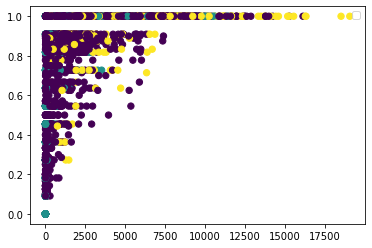

In [21]:
X=np.array(df)
plt.scatter(X[:,0],X[:,1],c=labels1,s=40,cmap="viridis")
plt.legend()